# Brownian motion and geometric Brownian motion

Simulate 5 paths of standard Brownian motion on $[0, 1]$, verify that
increments $B(t+h) - B(t)$ are $\mathcal{N}(0, h)$, then overlay 5 paths
of geometric Brownian motion.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

np.random.seed(0)

## 1. Standard Brownian motion

Discretise $[0, T]$ into $n$ steps of size $h = T/n$ and set
$B(t_{k+1}) = B(t_k) + \sqrt{h}\, Z_k$ with $Z_k \sim \mathcal{N}(0, 1)$ i.i.d.

In [2]:
T = 1.0
n = 1000
h = T / n
t = np.linspace(0, T, n + 1)
M = 5

dB = np.sqrt(h) * np.random.standard_normal(size=(M, n))
B = np.concatenate([np.zeros((M, 1)), np.cumsum(dB, axis=1)], axis=1)

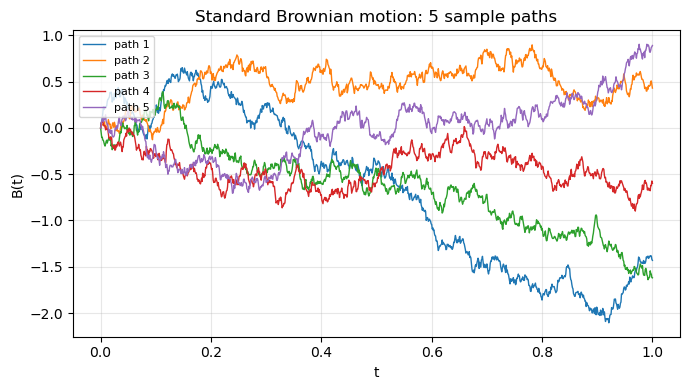

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
for i in range(M):
    ax.plot(t, B[i], lw=1.0, label=f"path {i+1}")
ax.set_xlabel("t")
ax.set_ylabel("B(t)")
ax.set_title("Standard Brownian motion: 5 sample paths")
ax.legend(loc="upper left", fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 2. Increments are $\mathcal{N}(0, h)$

Generate a large batch of one-step increments and compare their histogram
against the density of $\mathcal{N}(0, h)$.

Empirical mean      +0.00003   (theory 0)
Empirical variance  0.00098   (theory h = 0.001)


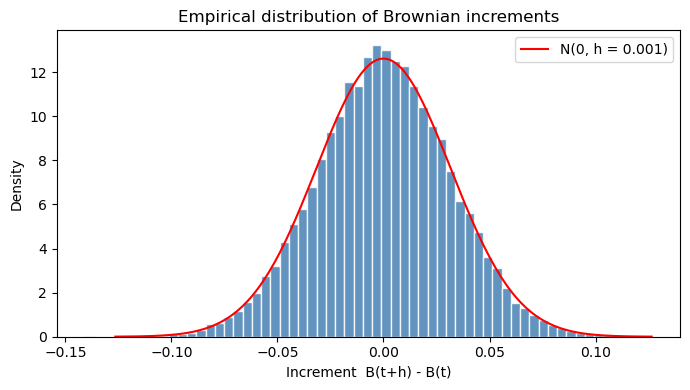

In [4]:
M_big = 20_000
inc = np.sqrt(h) * np.random.standard_normal(size=M_big)

print(f"Empirical mean      {inc.mean():+.5f}   (theory 0)")
print(f"Empirical variance  {inc.var(ddof=1):.5f}   (theory h = {h})")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(inc, bins=60, density=True, color="steelblue",
        edgecolor="white", alpha=0.85)
xs = np.linspace(-4 * np.sqrt(h), 4 * np.sqrt(h), 200)
ax.plot(xs, norm.pdf(xs, 0, np.sqrt(h)), "r-", lw=1.5,
        label=f"N(0, h = {h})")
ax.set_xlabel("Increment  B(t+h) - B(t)")
ax.set_ylabel("Density")
ax.set_title("Empirical distribution of Brownian increments")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Empirical mean and variance of $B(t)$ at a fixed $t$

For standard BM, $B(t) \sim \mathcal{N}(0, t)$, so at $t = 0.5$ we expect
mean $\approx 0$ and variance $\approx 0.5$. Run $M = 10\,000$ paths up to
$t = 0.5$.

In [5]:
M2 = 10_000
t_fixed = 0.5
n_fixed = int(t_fixed / h)
dB2 = np.sqrt(h) * np.random.standard_normal(size=(M2, n_fixed))
B_tfixed = dB2.sum(axis=1)

print(f"B(t={t_fixed}) empirical mean     {B_tfixed.mean():+.4f}  (theory 0)")
print(f"B(t={t_fixed}) empirical variance {B_tfixed.var(ddof=1):.4f}  (theory t = {t_fixed})")

B(t=0.5) empirical mean     +0.0031  (theory 0)
B(t=0.5) empirical variance 0.4923  (theory t = 0.5)


## 4. Geometric Brownian motion

$S(t) = S_0 \exp\left((\mu - \tfrac{1}{2} \sigma^2) t + \sigma B(t)\right)$.
Positive, lognormal at each $t$, multiplicative.

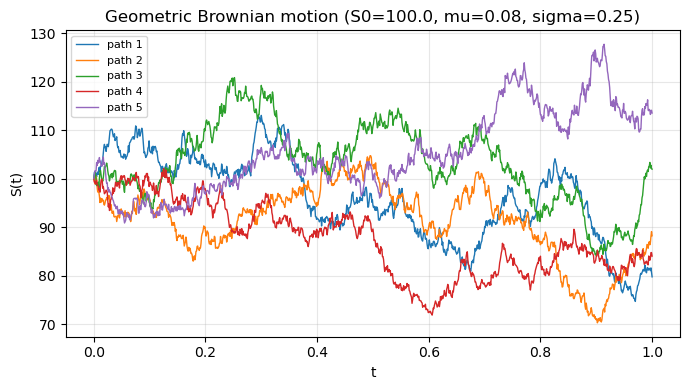

In [6]:
S0, mu, sigma = 100.0, 0.08, 0.25
dB3 = np.sqrt(h) * np.random.standard_normal(size=(M, n))
B3 = np.concatenate([np.zeros((M, 1)), np.cumsum(dB3, axis=1)], axis=1)
S = S0 * np.exp((mu - 0.5 * sigma**2) * t + sigma * B3)

fig, ax = plt.subplots(figsize=(7, 4))
for i in range(M):
    ax.plot(t, S[i], lw=1.0, label=f"path {i+1}")
ax.set_xlabel("t")
ax.set_ylabel("S(t)")
ax.set_title(f"Geometric Brownian motion (S0={S0}, mu={mu}, sigma={sigma})")
ax.legend(loc="upper left", fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Exercises

1. Compute the empirical quadratic variation $\sum_k (B(t_{k+1}) - B(t_k))^2$
   and verify it converges to $T$ as the mesh refines.
2. Simulate correlated Brownian motions $(B_1, B_2)$ with correlation
   $\rho = 0.6$ via a Cholesky factor.
3. Price a European call on the GBM above by Monte-Carlo and compare with
   the Black–Scholes formula (see the `finance-quantitative` notebook).